# Visium HD human colorectal cancer Landscape + Clustergram + Enrich

This tutorial explores a Visium HD human colorectal cancer (CRC) sample that was
already segmented into cells and clustered with Scanpy (220,703 cells, 15 Leiden
clusters). It shows the handoff from Scanpy to Celldega:

1. view the clustered cells in their tissue context with a **Landscape**,
2. summarize clusters in a **plain AnnData**: pseudobulk expression, the
   fraction of cells expressing each gene, and marker genes ranked per cluster,
3. explore the result in a **Clustergram** linked to the Landscape and to
   **Enrich** (Enrichr gene-set enrichment),
4. annotate clusters and genes interactively, and
5. sub-cluster the Goblet cells and color the sub-clusters by their depth along
   the colonic crypts.

Data source: [broadinstitute/Celldega_Supporting_Data](https://huggingface.co/datasets/broadinstitute/Celldega_Supporting_Data).
Files are downloaded once through direct Hugging Face `/resolve/main/` URLs, so
`huggingface_hub` is not a notebook dependency.

In [1]:
from importlib.metadata import version
from pathlib import Path
import shutil
from urllib.request import Request, urlopen
import warnings

import anndata as ad
import celldega as dega
import pandas as pd
from pandas.errors import PerformanceWarning
import scanpy as sc

print(f"celldega {version('celldega')}")
print(f"scanpy {version('scanpy')}")

warnings.filterwarnings("ignore", category=PerformanceWarning, module=r"scanpy\.tools\._rank_genes_groups")

celldega 0.26.1
scanpy 1.10.4


## Data

Two files are used, each downloaded on first run and reused afterwards:

- `crc_cluster.h5ad` (~1.6 GB): the Scanpy analysis, with log-normalized
  expression in `X`, Leiden clusters in `obs["leiden"]`, and a UMAP.
- `crc_raw_feature_cell_matrix.h5` (~280 MB): Space Ranger's cell-segmented count
  matrix for the same sample, which supplies the raw counts the analysis file
  does not keep.

In [2]:
HF_RESOLVE_BASE = (
    "https://huggingface.co/datasets/"
    "broadinstitute/Celldega_Supporting_Data/resolve/main"
)
CLUSTERED_FILENAME = "crc_cluster.h5ad"
RAW_COUNTS_FILENAME = "crc_raw_feature_cell_matrix.h5"

# Store data in the repository's notebooks/data folder when run from a checkout,
# otherwise beside the notebook.
working_dir = Path.cwd().resolve()
project_root = next(
    (
        d
        for d in (working_dir, *working_dir.parents)
        if (d / "pyproject.toml").is_file() and (d / "notebooks").is_dir()
    ),
    None,
)
data_dir = (project_root / "notebooks" if project_root else working_dir) / "data"
data_dir = data_dir / "visium-hd_data" / "Visium_HD_Human_Colon_Cancer"

data_dir.mkdir(parents=True, exist_ok=True)

# Download inputs once; the signatures below are recomputed directly.
input_files = {
    CLUSTERED_FILENAME: CLUSTERED_FILENAME,
    RAW_COUNTS_FILENAME: "raw_feature_cell_matrix.h5",
    "cluster-4_sub-cluster.h5ad": "cluster-4_sub-cluster.h5ad",
    "Meta_crypt_clusters_with_vivid_colors.csv": "Meta_crypt_clusters_with_vivid_colors.csv",
}
for remote, local in input_files.items():
    destination = data_dir / local
    if not destination.is_file():
        request = Request(f"{HF_RESOLVE_BASE}/{remote}", headers={"User-Agent": "celldega-example-notebook"})
        partial = destination.with_suffix(destination.suffix + ".part")
        with urlopen(request) as response, partial.open("wb") as output:
            shutil.copyfileobj(response, output)
        partial.replace(destination)

In [3]:
adata = sc.read_h5ad(data_dir / CLUSTERED_FILENAME)

# Visium HD's cell-segmented matrix uses the same cell barcodes
# ("cellid_000000003-1", ...). It lists every probe-set gene, some under
# duplicate symbols, so make names unique the same way Scanpy did before
# aligning to the analyzed cells and genes.
with warnings.catch_warnings():
    # Expected: fixed by var_names_make_unique() on the next line.
    warnings.filterwarnings("ignore", message="Variable names are not unique")
    raw = sc.read_10x_h5(data_dir / input_files[RAW_COUNTS_FILENAME])
raw.var_names_make_unique()
adata.layers["counts"] = raw[adata.obs_names, adata.var_names].X
del raw

adata

AnnData object with n_obs × n_vars = 220703 × 18132
    obs: 'clusters', 'orig_clusters', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'clusters', 'clusters_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

Plotting the UMAP also stores Scanpy's Leiden palette in
`adata.uns["leiden_colors"]`. The Landscape and Clustergram below
all read that palette, so every view colors a cluster the same way.

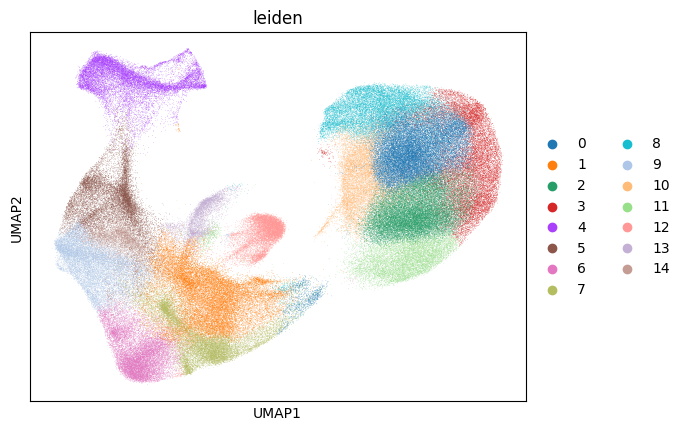

In [4]:
sc.pl.umap(adata, color="leiden")

## Landscape

The Landscape loads pre-tiled image and segmentation data (LandscapeFiles) from
`base_url` and takes cell metadata, including the Leiden clusters, from `adata`.

In [5]:
base_url = (
    "https://raw.githubusercontent.com/SharkieJones/celldega_Visium-HD_hCRC/"
    "refs/heads/main/Visium_HD_Human_Colon_Cancer_2025-10-25_2um"
)

landscape = dega.viz.Landscape(
    technology="Visium-HD",
    base_url=base_url,
    height=600,
    max_tiles_to_view=10,
    adata=adata,
)

/var/folders/2_/m2fbpk455xg3pbt2h6y9q6980000gn/T/ipykernel_63169/3932876498.py:6: UserWarning: Transformation matrix not found at https://raw.githubusercontent.com/SharkieJones/celldega_Visium-HD_hCRC/refs/heads/main/Visium_HD_Human_Colon_Cancer_2025-10-25_2um/micron_to_image_transform.csv. Using identity.
  landscape = dega.viz.Landscape(


## AnnData cluster signatures and marker genes

Aggregate raw counts with `sc.get.aggregate`. The resulting AnnData holds log1p-CPM
pseudobulk expression in `X`, detection fractions in `layers["fraction_expressing"]`,
and the shared cluster palette in `obs["color"]`. Run `sc.tl.rank_genes_groups`
on cell-level log-normalized `adata.X` and copy its results into
`signatures.uns["rank_genes_groups"]`. Each gene's best-scoring cluster colors its row.

In [6]:
signatures = sc.get.aggregate(adata, by="leiden", func=["sum", "count_nonzero"], layer="counts")
signatures.obs["n_cells"] = signatures.obs["leiden"].map(adata.obs["leiden"].value_counts()).astype(int)
signatures.X = signatures.layers["sum"].astype("float32")
signatures.layers["fraction_expressing"] = (
    signatures.layers["count_nonzero"] / signatures.obs["n_cells"].to_numpy()[:, None]
)
sc.pp.normalize_total(signatures, target_sum=1_000_000)
sc.pp.log1p(signatures)
palette = pd.Series(adata.uns["leiden_colors"], index=adata.obs["leiden"].cat.categories)
signatures.obs["color"] = signatures.obs["leiden"].map(palette)
signatures.uns["leiden_colors"] = palette.loc[signatures.obs["leiden"]].tolist()

# Test cell-level log-normalized expression, retaining ranks for every gene.
sc.tl.rank_genes_groups(adata, groupby="leiden", method="t-test",
                       use_raw=False, n_genes=adata.n_vars)
signatures.uns["rank_genes_groups"] = adata.uns["rank_genes_groups"]
markers = sc.get.rank_genes_groups_df(adata, group=None)
# Color each gene by the cluster where its marker score is highest.
best_group = markers.sort_values("scores", ascending=False).drop_duplicates("names").set_index("names")["group"]
signatures.var["leiden_marker"] = pd.Categorical(
    best_group.reindex(signatures.var_names), categories=adata.obs["leiden"].cat.categories,
)
signatures

AnnData object with n_obs × n_vars = 15 × 18132
    obs: 'leiden', 'n_cells', 'color'
    var: 'gene_ids', 'feature_types', 'genome', 'leiden_marker'
    uns: 'log1p', 'leiden_colors', 'rank_genes_groups'
    layers: 'sum', 'count_nonzero', 'fraction_expressing'

## Clustergram

The Matrix colors columns by cluster (`col_attr=["leiden"]`) and rows by each
gene's best-scoring cluster (`row_attr=["leiden_marker"]`), using the same
palette as the Landscape. All genes are hierarchically clustered; the
marker-ranked views add DIM slider levels with each cluster's top 1, 2, 3, ...
markers, each re-biclustered ahead of time. `rank_dim=3` opens on the top 3
markers per cluster.

In [7]:
marker_levels = [1, 2, 3, 5, 10, 25, 50, 75]

mat = dega.clust.Matrix(
    signatures, col_attr=["leiden"], row_attr=["leiden_marker"],
    col_entity={"entity": "cell", "attr": "leiden"},
)
mat.set_size_matrix(ad.AnnData(
    signatures.layers["fraction_expressing"], obs=signatures.obs.copy(), var=signatures.var.copy(),
))

# Z-score the Matrix copy; signatures retains the original values.
mat.norm("row", by="zscore")
mat.cluster(view="rank_genes_groups", levels=marker_levels)

for view in mat.views:
    print(f"{view['level']:>3} markers/cluster -> {view['n_rows']} genes")

cgm = dega.viz.Clustergram(
    matrix=mat,
    width=450,
    height=500,
    manual_col_cat="cell_type",
    manual_row_cat="info",
    rank_dim=3,
)

/Users/nicolasfernandez/Documents/celldega/src/celldega/clust/matrix.py:759: UserWarning: Found 17 constant features. Replacing zero std with small value to avoid inf/NaN.
  zscore_normalize_inplace(data_values, axis=0)


  1 markers/cluster -> 13 genes
  2 markers/cluster -> 21 genes
  3 markers/cluster -> 33 genes
  5 markers/cluster -> 52 genes
 10 markers/cluster -> 92 genes
 25 markers/cluster -> 231 genes
 50 markers/cluster -> 456 genes
 75 markers/cluster -> 681 genes


## Linked Landscape, Clustergram, and Enrich

- Click a column (cluster) label to highlight that cluster in the Landscape and
  send its top marker genes to Enrich.
- Click a gene (row) label to show that gene's expression in the Landscape.
- Select a dendrogram cluster of genes to run enrichment on that gene set.
- Drag the DIM slider to move between marker-ranked views and all genes.
- Use the ROW / COL dropdowns in the control panel to switch which category the
  bar plots summarize, and hover a category to locate it in the matrix.
- Annotate: select columns or rows (e.g. from a dendrogram) and assign a
  `cell_type` or `info` category. Annotations are colored in the matrix and
  summarized in the category bars.

In [8]:
linked_widgets = dega.viz.spatial_clustergram(
    landscape,
    cgm,
    enrich=True,
)

In [9]:
linked_widgets

## Sub-clustering Goblet cells along the crypt axis

Leiden cluster 4 (Goblet / mucin-secreting epithelial cells, 15,613 cells) lines the
colonic crypts. Re-clustering these cells reveals epithelial states that may vary along the
crypt axis. The ordering below is a working interpretation to check against
tissue position and the full expression signatures.

The sub-clusters were calculated from cluster 4's raw counts:

```python
goblet = sc.AnnData(adata[adata.obs["leiden"] == "4"].layers["counts"].copy())
sc.pp.normalize_total(goblet)
sc.pp.log1p(goblet)
sc.tl.pca(goblet)
sc.pp.neighbors(goblet, n_neighbors=30, metric="correlation")
sc.tl.leiden(goblet, flavor="igraph", resolution=1.0, random_state=0)
sc.tl.umap(goblet, min_dist=0.5, spread=2, random_state=0)
# Sub-clusters are then relabeled 0, 1, 2, ... from largest to smallest.
```

Here the precomputed result is downloaded instead. It has the same cell barcodes
as `adata`, log-normalized expression in `X`, sub-clusters in `obs["leiden"]`, and
a sub-cluster UMAP.

Sub-clusters 3 and 6 remain excluded from this working selection. They retain
Goblet-marker expression, so this exclusion needs review and is not a validated
cell-type annotation. The remaining nine sub-clusters keep their original
Leiden labels and UMAP coordinates.

In [10]:
GOBLET_FILENAME = "cluster-4_sub-cluster.h5ad"
CRYPT_COLORS_FILENAME = "Meta_crypt_clusters_with_vivid_colors.csv"

EXCLUDED_SUB_CLUSTERS = ["3", "6"]

goblet = sc.read_h5ad(data_dir / GOBLET_FILENAME)
goblet = goblet[~goblet.obs["leiden"].isin(EXCLUDED_SUB_CLUSTERS)].copy()
goblet.obs["leiden"] = goblet.obs["leiden"].cat.remove_unused_categories()

goblet.obs["leiden"].value_counts()

leiden
0     2224
1     2077
2     1815
4     1738
5     1498
7     1086
8      781
9      731
10     595
Name: count, dtype: int64

### Ordering the sub-clusters along the crypt

Use three genes to orient the clusters, then explore their full signatures in
the Clustergram below. These references describe human colonic epithelium;
their gradients are hypotheses to check in this cancer section.

| Gene | Orientation cue | Reference |
| --- | --- | --- |
| **OLFM4** | Crypt-base stem/progenitor-associated expression; not Goblet-specific. | [Reynolds et al., 2014, Fig. 1](https://gut.bmj.com/content/63/4/610) |
| **CLCA1** | Goblet-associated expression, with a lower-crypt gradient in healthy colon. | [Parikh et al., 2019, Fig. 4b](https://www.nature.com/articles/s41586-019-0992-y) |
| **GUCA2A** | Surface-associated expression in both Goblet cells and colonocytes. | [Brenna et al., 2016, Fig. 1f](https://link.springer.com/article/10.1007/s00441-016-2393-y) |

The line plot shows mean log-normalized expression, z-scored across sub-clusters
within each gene. The x-axis is the proposed cluster order, not physical distance
or a fitted trajectory. `crypt_depth` is an ordinal label (9 to 1), and the colors
are a display gradient. Expression does not independently validate this order.

Sub-clusters 7 and 9 occupy separate crypts and have uncertain positions on the
axis. Show them as unconnected points in the shaded region rather than extending
the proposed gradient through them. The unscaled means remain in `crypt`.


In [11]:
# The CSV supplies the display gradient used by the spatial widgets.
crypt_palette = pd.read_csv(data_dir / CRYPT_COLORS_FILENAME)["color_hex"]
CRYPT_ORDER = ["10", "0", "5", "1", "8", "4", "2", "7", "9"]
AXIS_MARKERS = ["OLFM4", "CLCA1", "GUCA2A"]

crypt = pd.DataFrame(
    {
        "crypt_depth": range(len(CRYPT_ORDER), 0, -1),  # Working ordinal labels.
        "color": crypt_palette.to_numpy(),
    },
    index=pd.Index(CRYPT_ORDER, name="sub_cluster"),
)
crypt = crypt.join(
    sc.get.obs_df(goblet, AXIS_MARKERS).groupby(goblet.obs["leiden"], observed=True).mean()
)


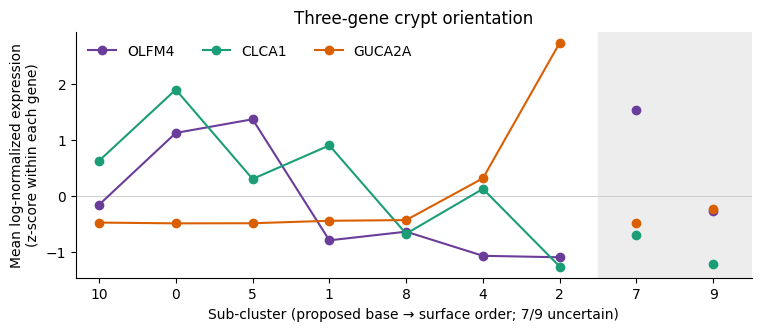

In [12]:
import matplotlib.pyplot as plt

means = crypt[AXIS_MARKERS]
profiles = (means - means.mean()) / means.std(ddof=0).replace(0, 1)
fig, ax = plt.subplots(figsize=(7.5, 3.2), layout="constrained")
for gene, color in zip(AXIS_MARKERS, ["#6a3d9a", "#1b9e77", "#d95f02"]):
    ax.plot(range(7), profiles[gene].iloc[:7], marker="o", color=color, label=gene)
    ax.scatter([7, 8], profiles[gene].iloc[7:], color=color)
ax.axvspan(6.5, 8.5, color="0.93", zorder=0)
ax.axhline(0, color="0.8", linewidth=0.7, zorder=0)
ax.set_xticks(range(len(CRYPT_ORDER)), CRYPT_ORDER)
ax.set_xlim(-0.3, 8.5)
ax.set_xlabel("Sub-cluster (proposed base → surface order; 7/9 uncertain)")
ax.set_ylabel("Mean log-normalized expression\n(z-score within each gene)")
ax.set_title("Three-gene crypt orientation")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()


**Shared expression and possible spillover.** GUCA2A alone is not evidence of
colonocyte contamination. CA1 and SLC26A3 are stronger absorptive-lineage flags;
KRT20 can also occur in Goblet cells throughout the crypt ([Dalerba et al., 2011,
Fig. 1 and Supplementary Fig. 13](https://www.nature.com/articles/nbt.2038)). In this
dataset, SLC26A3 is detected in 95%/82% of cells in sub-clusters 2/4, while MUC2
is detected in 68%/88%. Review their full signatures and segmentation: a shared
program, mixed cell identities and spatial leakage remain competing explanations.

Sub-clusters 7/9 co-detect LCN2 and DUOX2 in 75%/91% of cells, while PTPRC is
detected in less than 1%. An epithelial antimicrobial state is plausible:
[Li et al., 2024](https://www.nature.com/articles/s41467-024-51580-7) validates such
co-expression in Crohn's disease epithelium. This is contextual evidence, not a
diagnosis or proof that leakage is absent. These genes are not used as depth anchors.

Detection means expression > 0 in the supplied log-normalized cell matrix.
Use the signature Clustergram's tile sizes (fraction expressing), per-cell
co-expression and spatial boundaries to investigate; cluster averages alone
cannot establish spillover.


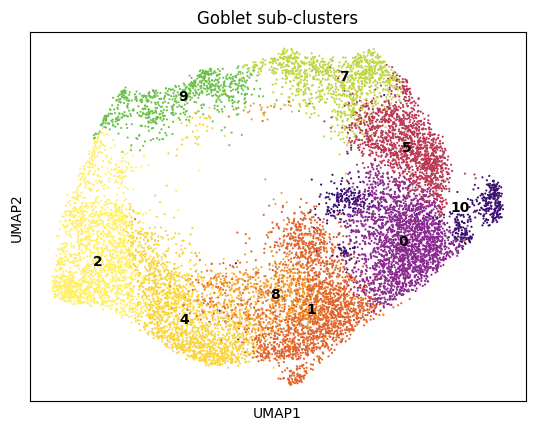

In [13]:
# Store the gradient as Scanpy's palette (one color per sub-cluster, in category
# order) so the Landscape and Clustergram all use it.
sub_clusters = goblet.obs["leiden"].cat.categories
goblet.uns["leiden_colors"] = crypt.loc[sub_clusters, "color"].tolist()

sc.pl.umap(goblet, color="leiden", legend_loc="on data", title="Goblet sub-clusters")

### Sub-cluster signatures and marker genes

The sub-clusters are summarized in an AnnData, the same way as the
clusters above. Raw counts come from the main `adata`, which has the same cells
and genes. This Clustergram retains the full gene space: use its DIM slider
(0 = all genes) to explore beyond the three orientation markers.

Each sub-cluster's `crypt_depth` is added as a numeric column attribute.
Double-click its label in the Clustergram to order the sub-clusters from the
crypt base (left) to the surface (right).

Genes get the same attribute: after the marker ranking, each gene takes the
depth of its best-scoring sub-cluster (`var["leiden_marker"]`). Double-click the
row attribute label to order marker genes from the crypt base (top) to the
surface (bottom). Genes without a marker score have depth 0.

In [14]:
goblet.layers["counts"] = adata[goblet.obs_names, goblet.var_names].layers["counts"]

goblet_signatures = sc.get.aggregate(goblet, by="leiden", func=["sum", "count_nonzero"], layer="counts")
goblet_signatures.obs["n_cells"] = goblet_signatures.obs["leiden"].map(goblet.obs["leiden"].value_counts()).astype(int)
goblet_signatures.X = goblet_signatures.layers["sum"].astype("float32")
goblet_signatures.layers["fraction_expressing"] = (
    goblet_signatures.layers["count_nonzero"] / goblet_signatures.obs["n_cells"].to_numpy()[:, None]
)
sc.pp.normalize_total(goblet_signatures, target_sum=1_000_000)
sc.pp.log1p(goblet_signatures)
palette = pd.Series(goblet.uns["leiden_colors"], index=goblet.obs["leiden"].cat.categories)
goblet_signatures.obs["color"] = goblet_signatures.obs["leiden"].map(palette)
goblet_signatures.uns["leiden_colors"] = palette.loc[goblet_signatures.obs["leiden"]].tolist()

# Test cell-level log-normalized expression, retaining ranks for every gene.
sc.tl.rank_genes_groups(goblet, groupby="leiden", method="t-test",
                       use_raw=False, n_genes=goblet.n_vars)
goblet_signatures.uns["rank_genes_groups"] = goblet.uns["rank_genes_groups"]
markers = sc.get.rank_genes_groups_df(goblet, group=None)
# Color each gene by the cluster where its marker score is highest.
best_group = markers.sort_values("scores", ascending=False).drop_duplicates("names").set_index("names")["group"]
goblet_signatures.var["leiden_marker"] = pd.Categorical(
    best_group.reindex(goblet_signatures.var_names), categories=goblet.obs["leiden"].cat.categories,
)

# Map the working crypt order onto both sub-clusters and their marker genes.
goblet_signatures.obs["crypt_depth"] = goblet_signatures.obs["leiden"].map(crypt["crypt_depth"]).astype(int)
goblet_signatures.var["crypt_depth"] = (
    goblet_signatures.var["leiden_marker"].astype(object).map(crypt["crypt_depth"]).fillna(0).astype(int)
)

mat_goblet = dega.clust.Matrix(
    goblet_signatures, col_attr=["leiden", "crypt_depth"], row_attr=["leiden_marker", "crypt_depth"],
    col_entity={"entity": "cell", "attr": "leiden"},
)
mat_goblet.set_size_matrix(ad.AnnData(
    goblet_signatures.layers["fraction_expressing"], obs=goblet_signatures.obs.copy(), var=goblet_signatures.var.copy(),
))
mat_goblet.norm("row", by="zscore")
mat_goblet.cluster(view="rank_genes_groups", levels=marker_levels)

cgm_goblet = dega.viz.Clustergram(
    matrix=mat_goblet,
    width=450,
    height=500,
    rank_dim=3,
)

/Users/nicolasfernandez/Documents/celldega/src/celldega/clust/matrix.py:759: UserWarning: Found 416 constant features. Replacing zero std with small value to avoid inf/NaN.
  zscore_normalize_inplace(data_values, axis=0)


### Goblet sub-clusters in the tissue

Only the retained cells are colored in this Landscape. Under the proposed
orientation, purple indicates the crypt base and yellow the surface; the green crypts in
the upper region are sub-clusters 7 and 9. Click a sub-cluster
column in the Clustergram to highlight its cells in the tissue and send its top
marker genes to Enrich. In the Landscape, switch to the UMAP view to see the
sub-cluster embedding.

In [15]:
landscape_goblet = dega.viz.Landscape(
    technology="Visium-HD",
    base_url=base_url,
    height=600,
    max_tiles_to_view=10,
    adata=goblet,
)

goblet_widgets = dega.viz.spatial_clustergram(
    landscape_goblet,
    cgm_goblet,
    enrich=True,
)

/var/folders/2_/m2fbpk455xg3pbt2h6y9q6980000gn/T/ipykernel_63169/2718312708.py:1: UserWarning: Transformation matrix not found at https://raw.githubusercontent.com/SharkieJones/celldega_Visium-HD_hCRC/refs/heads/main/Visium_HD_Human_Colon_Cancer_2025-10-25_2um/micron_to_image_transform.csv. Using identity.
  landscape_goblet = dega.viz.Landscape(


In [16]:
goblet_widgets